# 04 – Dotýkající se mince (watershed, Hough)

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import cv2
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from coins.io import load_rgb, show_images, SAMPLE_DIR
from coins.preprocess import preprocess
from coins.segment import segment, split_touching, find_coins, draw_coins

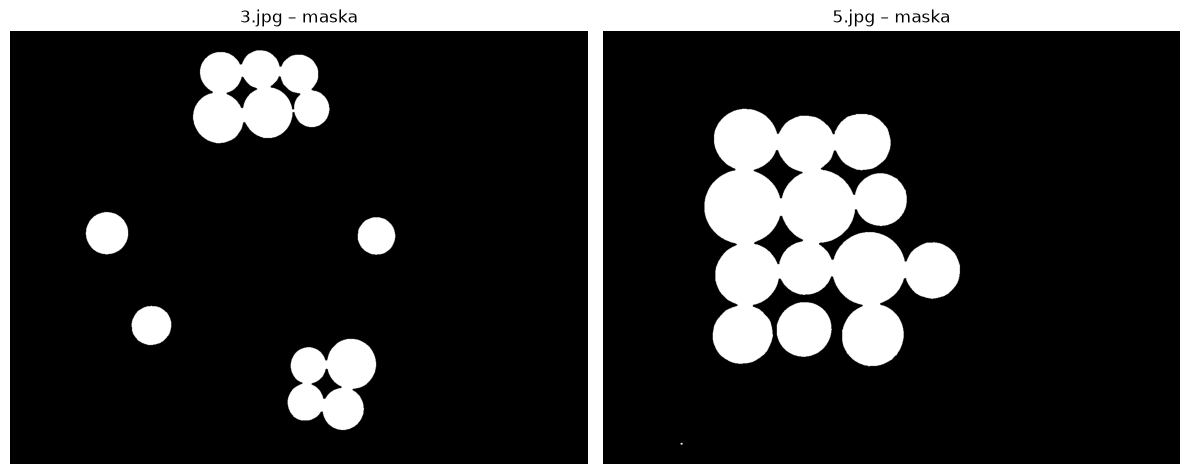

In [2]:
TRUTH = {"1.jpg": 11, "2.jpg": 2, "3.jpg": 13, "4.jpg": 4, "5.jpg": 13}

images = {name: load_rgb(SAMPLE_DIR / name) for name in TRUTH}
masks = {name: segment(preprocess(img)) for name, img in images.items()}

show_images([masks["3.jpg"], masks["5.jpg"]], ["3.jpg – maska", "5.jpg – maska"], cols=2, size=6)

## Bez rozdělení

In [3]:
pd.DataFrame([
    {"snímek": n, "skutečně": TRUTH[n], "nalezeno": len(find_coins(masks[n]))} for n in TRUTH
])

,snímek,skutečně,nalezeno
0,1.jpg,11,11
1,2.jpg,2,2
2,3.jpg,13,3
3,4.jpg,4,0
4,5.jpg,13,1


## Distance transform → markery → watershed

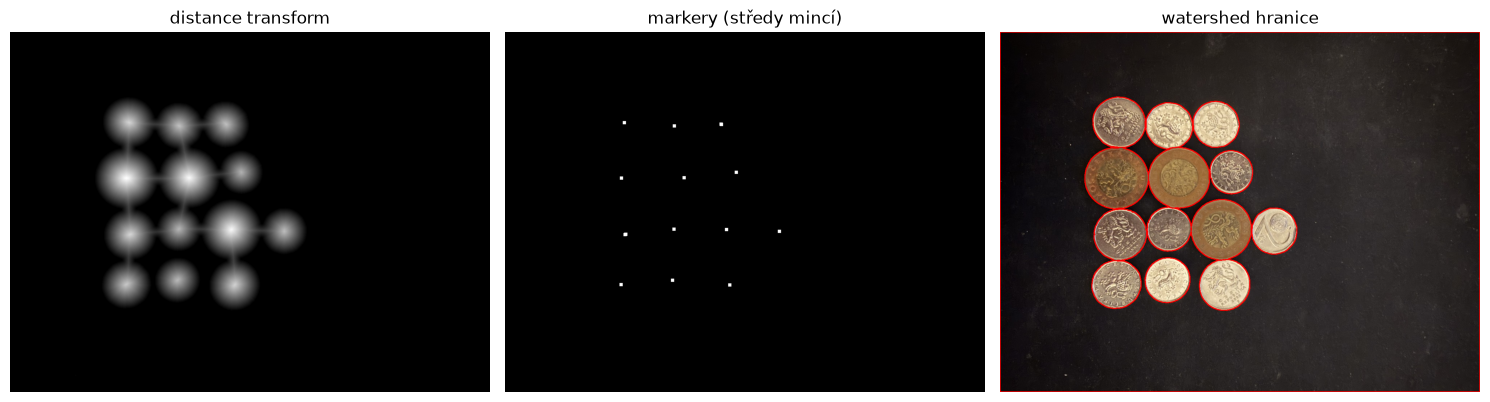

In [4]:
mask = masks["5.jpg"]
dist = cv2.distanceTransform(mask, cv2.DIST_L2, 5)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))
peaks = (dist == cv2.dilate(dist, kernel)) & (dist > 0.4 * dist.max())
peaks = cv2.dilate(peaks.astype(np.uint8) * 255, np.ones((9, 9), np.uint8))

labels = split_touching(images["5.jpg"], mask)
borders = images["5.jpg"].copy()
borders[cv2.dilate((labels == -1).astype(np.uint8), np.ones((3, 3), np.uint8)) > 0] = (255, 0, 0)

show_images([dist, peaks, borders], ["distance transform", "markery (středy mincí)", "watershed hranice"], cols=3, size=5)

In [5]:
ws = {n: find_coins(masks[n], split_touching(images[n], masks[n])) for n in TRUTH}

pd.DataFrame([
    {"snímek": n, "skutečně": TRUTH[n], "watershed": len(ws[n])} for n in TRUTH
])

,snímek,skutečně,watershed
0,1.jpg,11,11
1,2.jpg,2,2
2,3.jpg,13,13
3,4.jpg,4,4
4,5.jpg,13,13


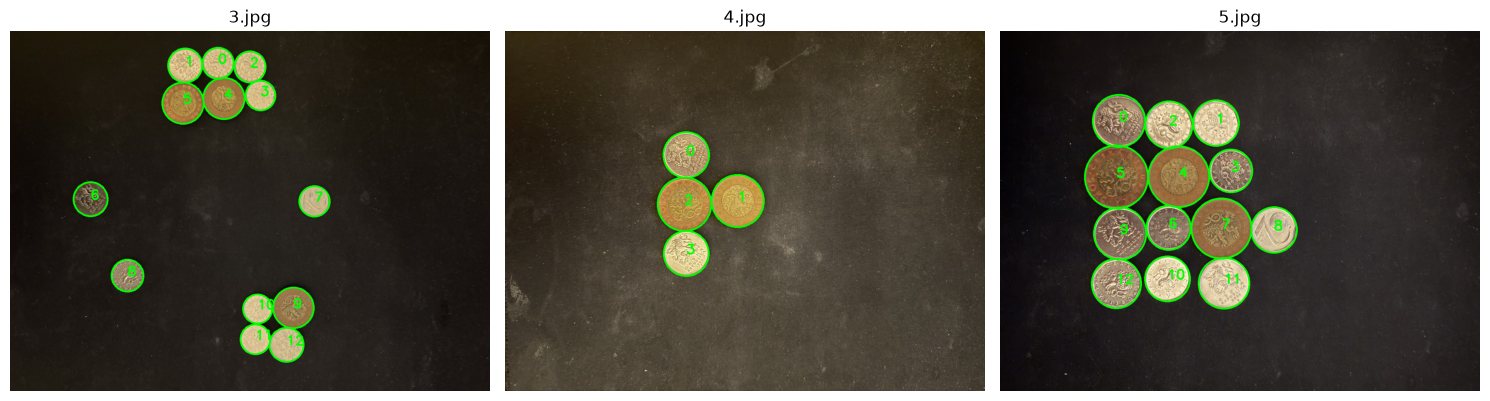

In [6]:
show_images([draw_coins(images[n], ws[n]) for n in ["3.jpg", "4.jpg", "5.jpg"]], ["3.jpg", "4.jpg", "5.jpg"], cols=3, size=5)

## Srovnání: Houghova transformace

In [7]:
def hough(v, param2):
    c = cv2.HoughCircles(v, cv2.HOUGH_GRADIENT, dp=1.2, minDist=70,
                         param1=100, param2=param2, minRadius=35, maxRadius=100)
    return [] if c is None else c[0]

v_all = {n: preprocess(img) for n, img in images.items()}
rows = []
for p2 in [30, 40, 50]:
    row = {"param2": p2}
    row.update({n: f"{len(hough(v_all[n], p2))}/{TRUTH[n]}" for n in TRUTH})
    rows.append(row)
rows.append({"param2": "watershed", **{n: f"{len(ws[n])}/{TRUTH[n]}" for n in TRUTH}})
pd.DataFrame(rows)

,param2,1.jpg,2.jpg,3.jpg,4.jpg,5.jpg
0,30,14/11,6/2,13/13,6/4,31/13
1,40,11/11,2/2,13/13,4/4,21/13
2,50,11/11,2/2,13/13,4/4,14/13
3,watershed,11/11,2/2,13/13,4/4,13/13


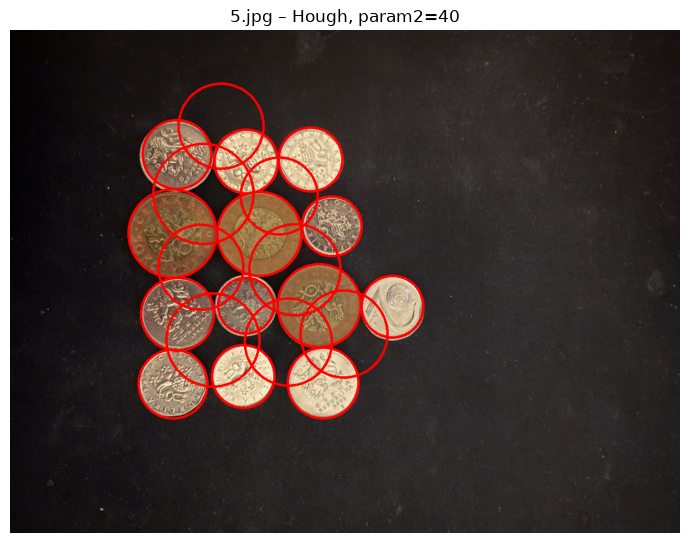

In [8]:
vis = images["5.jpg"].copy()
for x, y, r in hough(v_all["5.jpg"], 40):
    cv2.circle(vis, (int(x), int(y)), int(r), (255, 0, 0), 3)
show_images([vis], ["5.jpg – Hough, param2=40"], size=7)

In [9]:
out = ROOT / "results"
pd.DataFrame([
    {"snímek": n, "id": i, "x": round(c["x"]), "y": round(c["y"]), "r_px": round(c["r"], 1),
     "plocha_px": round(c["area"]), "kruhovitost": round(c["circularity"], 2)}
    for n, coins in ws.items() for i, c in enumerate(coins)
]).to_csv(out / "04_mince.csv", index=False)

for n in ["3.jpg", "4.jpg", "5.jpg"]:
    cv2.imwrite(str(out / f"04_{Path(n).stem}.jpg"),
                cv2.cvtColor(draw_coins(images[n], ws[n]), cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 80])